# Практическая работа № 2 — Разведочный анализ данных (EDA)
**Вариант A**

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Works from the repository root or from the notebooks/ folder
candidates = [Path("data/tips_sample.csv"), Path("../data/tips_sample.csv")]
data_path = next((p for p in candidates if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("Place tips_sample.csv in the data/ folder.")
df = pd.read_csv(data_path)
df.head()


,total_bill,size,day,time,tip
0,24.44,1,Fri,Lunch,4.62
1,13.68,3,Sat,Dinner,2.99
2,28.00,2,Sun,Dinner,5.01
3,NaN,4,Sun,Lunch,5.85
4,6.39,4,Fri,Dinner,2.13


In [2]:
print("Информация о данных:")
df.info()
print("\\nПропуски:")
display(df.isnull().sum().to_frame("missing_count"))


Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 160 entries, 0 to 159
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  156 non-null    float64
 1   size        160 non-null    int64  
 2   day         158 non-null    object 
 3   time        160 non-null    object 
 4   tip         160 non-null    float64
dtypes: float64(2), int64(1), object(2)
memory usage: 6.4+ KB
\nПропуски:


,missing_count
total_bill,4
size,0
day,2
time,0
tip,0


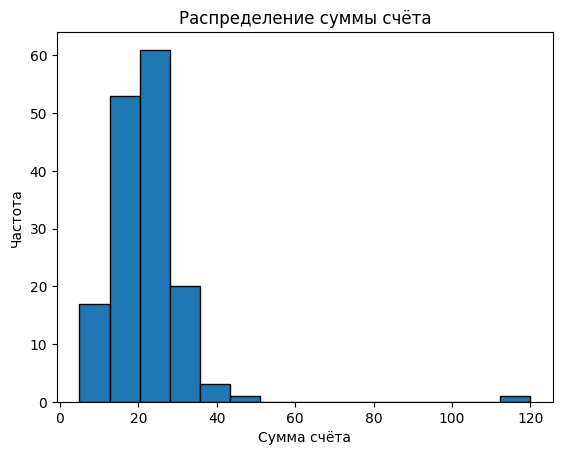

In [3]:
# Гистограмма числового признака
df["total_bill"].dropna().plot(kind="hist", bins=15, edgecolor="black")
plt.title("Распределение суммы счёта")
plt.xlabel("Сумма счёта")
plt.ylabel("Частота")
plt.show()


**Вывод:** основная масса значений суммы счёта находится в обычном диапазоне; необычно большое значение может растягивать распределение.

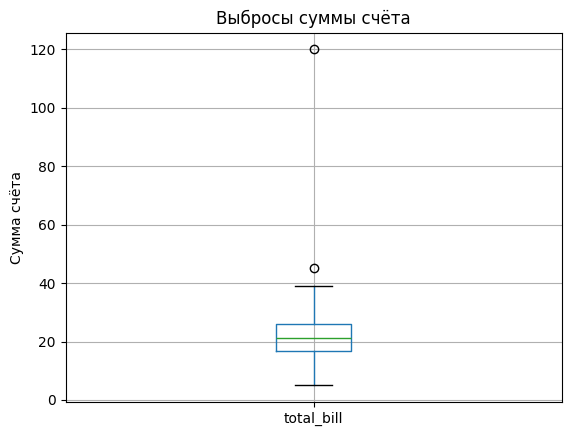

In [4]:
# Boxplot того же признака
df.boxplot(column="total_bill")
plt.title("Выбросы суммы счёта")
plt.ylabel("Сумма счёта")
plt.show()


**Вывод:** точки за пределами «усов» могут указывать на выбросы. Их нужно проверить по исходным данным, а не удалять автоматически.

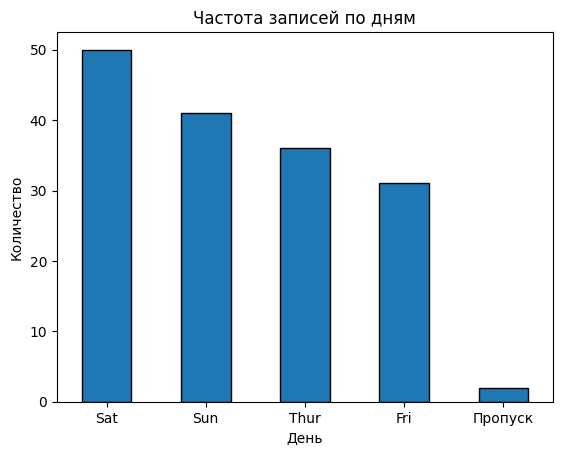

In [5]:
# Частоты категориального признака
df["day"].fillna("Пропуск").value_counts().plot(kind="bar", edgecolor="black")
plt.title("Частота записей по дням")
plt.xlabel("День")
plt.ylabel("Количество")
plt.xticks(rotation=0)
plt.show()


In [6]:
# Итоговая таблица «Проблема данных — где обнаружена»
problems = []
for col, count in df.isnull().sum().items():
    if count:
        problems.append({"Проблема данных": f"Пропуски ({count})", "Где обнаружена": col})
problems.append({"Проблема данных": "Потенциальный выброс", "Где обнаружена": "total_bill (проверить значение 120.0)"})
display(pd.DataFrame(problems))


,Проблема данных,Где обнаружена
0,Пропуски (4),total_bill
1,Пропуски (2),day
2,Потенциальный выброс,total_bill (проверить значение 120.0)
